In [ ]:
!pip install pyomo highspy >/dev/null

Adaptive Model built successfully.


Non-Adaptive Model built successfully.


/tmp/ipython-input-4097228879.py:245: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(Omega))


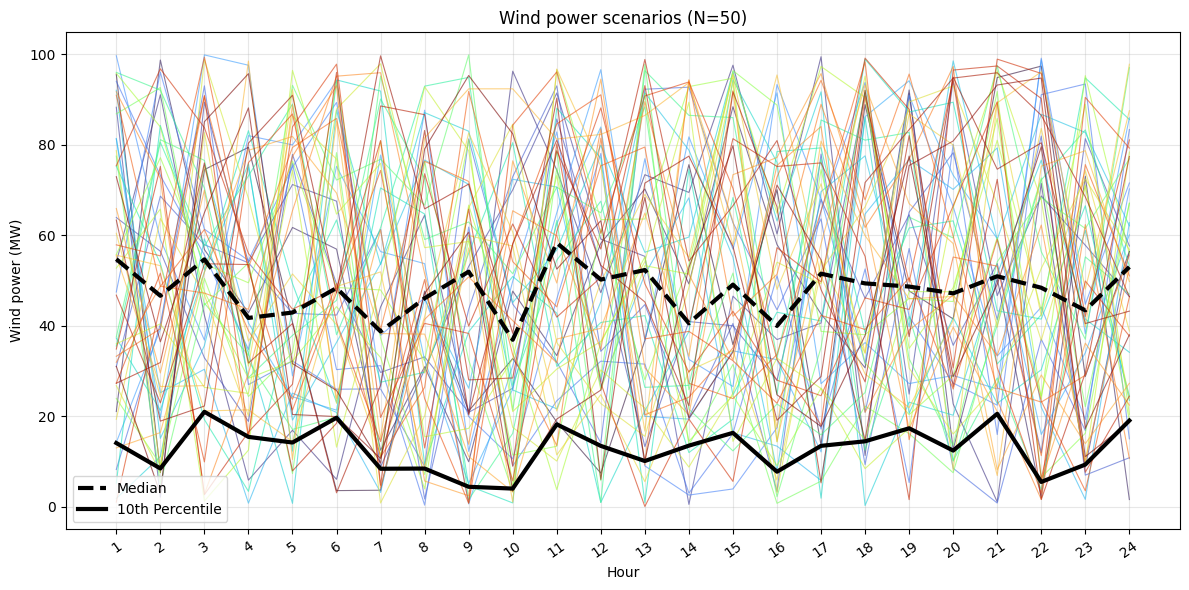

In [1]:
import pyomo.environ as pyo
from pyomo.opt import SolverFactory
import random

random.seed(17)
# Attempt to import matplotlib for plotting
try:
    import matplotlib.pyplot as plt
    import numpy as np
    _has_matplotlib = True
except ImportError:
    _has_matplotlib = False

# --- Helper function to create dummy data based on the article's descriptions ---
def create_dummy_data():
    """Generates a small, illustrative set of data for the Pyomo models."""
    T_set = list(range(1, 25))  # 24 hours in a day
    Omega_set = list(range(1, 51))  # 50 wind scenarios

    R_t = {t: random.uniform(15, 70) for t in T_set}  # Market prices ($/MWh)
    B_t = {t: 50 for t in T_set}  # Generation cost ($/MWh)
    epsilon = 0.05  # Probability threshold for failure
    Delta = 50      # Ramping rate (MW)
    U = 3           # Minimum up-time (hours)
    V = 3           # Minimum down-time (hours)
    G = 130         # Maximum power output (MW)
    g = 20          # Minimum power output (MW)

    # Generate wind scenarios (dummy data for illustration)
    w_t_omega = {(t, omega): random.uniform(0, 100) for t in T_set for omega in Omega_set}

    # Sort wind values for the extended-variable formulation
    sorted_w_values = {}
    flat_sorted_w_values = {}
    for t in T_set:
        wind_at_t = sorted([w_t_omega[t, omega] for omega in Omega_set])
        sorted_w_values[t] = {l: val for l, val in enumerate(wind_at_t, 1)}
        for l, val in enumerate(wind_at_t, 1):
            flat_sorted_w_values[(t, l)] = val

    return T_set, Omega_set, R_t, B_t, epsilon, Delta, U, V, G, g, w_t_omega, flat_sorted_w_values

# --- Adaptive Model ---
def build_adaptive_model(data):
    """
    Builds the Pyomo model for the adaptive hybrid generator system.
    This is a two-stage stochastic program with a joint chance constraint.
    The recourse decisions (y, r, u, v) are made after the wind scenario is observed.
    We use the big-M formulation for the chance constraint, as described in the article.
    """
    T, Omega, R, B, epsilon, Delta, U, V, G, g, w, _ = data

    model = pyo.ConcreteModel()

    # Sets
    model.T = pyo.Set(initialize=T)
    model.Omega = pyo.Set(initialize=Omega)

    # Parameters
    model.R = pyo.Param(model.T, initialize=R)
    model.B = pyo.Param(model.T, initialize=B)
    model.w = pyo.Param(model.T, model.Omega, initialize=w)
    model.epsilon = pyo.Param(initialize=epsilon)
    model.Delta = pyo.Param(initialize=Delta)
    model.U = pyo.Param(initialize=U)
    model.V = pyo.Param(initialize=V)
    model.G = pyo.Param(initialize=G)
    model.g = pyo.Param(initialize=g)

    # Variables
    # First-stage decision: promised power output, scenario-independent
    model.x = pyo.Var(model.T, domain=pyo.NonNegativeReals)

    # Second-stage recourse decisions: scenario-dependent
    model.y = pyo.Var(model.T, model.Omega, domain=pyo.NonNegativeReals)  # Generator output above g
    model.r = pyo.Var(model.T, model.Omega, domain=pyo.Binary)           # Generator on/off status
    model.u = pyo.Var(model.T, model.Omega, domain=pyo.Binary)           # Generator start-up status
    model.v = pyo.Var(model.T, model.Omega, domain=pyo.Binary)           # Generator shutdown status

    # Helper variable for chance constraint formulation
    model.z = pyo.Var(model.Omega, domain=pyo.Binary)

    # Objective: Maximize profit (revenue - expected cost)
    def objective_rule(model):
        expected_cost = sum(model.B[t] * (model.y[t, omega] + model.g * model.r[t, omega])
                            for t in model.T for omega in model.Omega) / len(model.Omega)
        revenue = sum(model.R[t] * model.x[t] for t in model.T)
        return revenue - expected_cost
    model.objective = pyo.Objective(rule=objective_rule, sense=pyo.maximize)

    # Constraints
    model.constraints = pyo.ConstraintList()

    # Joint Chance Constraint (JCC) - big-M formulation
    # The constraint P(...) >= 1 - epsilon is modeled by limiting the number of failures
    # to at most floor(N*epsilon). A "failure" is when the combined output is less than x_t.
    # We use a big-M value to relax the inequality when a failure occurs (z[omega] == 1).
    # M must be large enough. A safe upper bound for the right side is G + 100 (for wind).
    M = model.G + 100
    for t in model.T:
        for omega in model.Omega:
            model.constraints.add(model.x[t] <= model.y[t, omega] + model.g * model.r[t, omega] + model.w[t, omega] + M * model.z[omega])

    # Limit total number of failures
    model.constraints.add(sum(model.z[omega] for omega in model.Omega) <= pyo.floor(len(model.Omega) * model.epsilon))

    # Generator operating constraints (Y)
    # Ramping constraints
    for t in model.T:
        if t < len(model.T):
            model.constraints.add(model.y[t+1, omega] - model.y[t, omega] <= model.Delta * (model.u[t+1, omega] + model.r[t, omega]))
            model.constraints.add(model.y[t, omega] - model.y[t+1, omega] <= model.Delta * (model.v[t+1, omega] + model.r[t+1, omega]))

    # Minimum up/down-time constraints
    for t in model.T:
        if t >= model.U:
            model.constraints.add(sum(model.u[k, omega] for k in range(t - model.U + 1, t + 1)) <= model.r[t, omega])
        if t >= model.V:
            model.constraints.add(sum(model.v[k, omega] for k in range(t - model.V + 1, t + 1)) <= 1 - model.r[t, omega])

    # On/off status variables
    for t in model.T:
        if t > 1:
            model.constraints.add(model.u[t, omega] - model.v[t, omega] == model.r[t, omega] - model.r[t-1, omega])

    # Generator output limits
    for t in model.T:
        model.constraints.add((model.G - model.g) * model.r[t, omega] >= model.y[t, omega])

    return model


# --- Non-Adaptive Model ---
def build_non_adaptive_model(data):
    """
    Builds the Pyomo model for the non-adaptive hybrid generator system.
    All decisions, including generator dispatch, are made in the first stage,
    before wind power realizations are known.
    We use the extended-variable formulation for the joint chance constraint.
    """
    T, Omega, R, B, epsilon, Delta, U, V, G, g, _, sorted_w = data

    model = pyo.ConcreteModel()

    # Sets
    model.T = pyo.Set(initialize=T)
    # The l_indices for the extended variable formulation should align with the sorted scenarios
    model.l_indices = pyo.Set(initialize=range(1, len(Omega)))

    # Parameters
    model.R = pyo.Param(model.T, initialize=R)
    model.B = pyo.Param(model.T, initialize=B)
    model.w_sorted = pyo.Param(model.T, range(1, len(Omega) + 1), initialize=sorted_w)
    model.epsilon = pyo.Param(initialize=epsilon)
    model.Delta = pyo.Param(initialize=Delta)
    model.U = pyo.Param(initialize=U)
    model.V = pyo.Param(initialize=V)
    model.G = pyo.Param(initialize=G)
    model.g = pyo.Param(initialize=g)

    # Variables
    # All decisions are first-stage and scenario-independent
    model.x = pyo.Var(model.T, domain=pyo.NonNegativeReals)
    model.y = pyo.Var(model.T, domain=pyo.NonNegativeReals)
    model.r = pyo.Var(model.T, domain=pyo.Binary)
    model.u = pyo.Var(model.T, domain=pyo.Binary)
    model.v = pyo.Var(model.T, domain=pyo.Binary)

    # Helper variables for extended-variable formulation
    model.z = pyo.Var(range(1, len(Omega) + 1), domain=pyo.Binary)
    model.q = pyo.Var(model.T, model.l_indices, domain=pyo.NonNegativeReals, bounds=(0, 1))

    # Objective: Maximize profit (revenue - cost)
    def objective_rule(model):
        cost = sum(model.B[t] * (model.y[t] + model.g * model.r[t]) for t in model.T)
        revenue = sum(model.R[t] * model.x[t] for t in model.T)
        return revenue - cost
    model.objective = pyo.Objective(rule=objective_rule, sense=pyo.maximize)

    # Constraints
    model.constraints = pyo.ConstraintList()

    # Joint Chance Constraint (JCC) - extended-variable formulation
    for t in model.T:
        model.constraints.add(model.x[t] <= model.y[t] + model.g * model.r[t] + model.w_sorted[t, 1] +
                              sum((model.w_sorted[t, l+1] - model.w_sorted[t, l]) * model.q[t, l] for l in model.l_indices))

    # The q variable links the sorted wind values to the z variable
    for t in model.T:
        for l in model.l_indices:
            model.constraints.add(model.q[t, l] <= model.z[l])

    # The q variable enforces a consecutive-one property
    for t in model.T:
        for l in range(1, len(Omega) - 1):
            model.constraints.add(model.q[t, l+1] <= model.q[t, l])

    # Limit total number of failures
    model.constraints.add(sum(model.z[omega] for omega in range(1, len(Omega)+1)) <= pyo.floor(len(Omega) * model.epsilon))

    # Generator operating constraints (Y)
    # Ramping constraints
    for t in model.T:
        if t < len(model.T):
            model.constraints.add(model.y[t+1] - model.y[t] <= model.Delta * (model.u[t+1] + model.r[t]))
            model.constraints.add(model.y[t] - model.y[t+1] <= model.Delta * (model.v[t+1] + model.r[t+1]))

    # Minimum up/down-time constraints
    for t in model.T:
        if t >= model.U:
            model.constraints.add(sum(model.u[k] for k in range(t - model.U + 1, t + 1)) <= model.r[t])
        if t >= model.V:
            model.constraints.add(sum(model.v[k] for k in range(t - model.V + 1, t + 1)) <= 1 - model.r[t])

    # On/off status variables
    for t in model.T:
        if t > 1:
            model.constraints.add(model.u[t] - model.v[t] == model.r[t] - model.r[t-1])

    # Generator output limits
    for t in model.T:
        model.constraints.add((model.G - model.g) * model.r[t] >= model.y[t])

    return model


def plot_wind_scenarios(data, cmap_name="turbo"):
    """
    Plotea los escenarios de viento:
      - Una línea fina por escenario con color distinto (colormap).
      - Línea negra gruesa discontinua = Mediana.
      - Línea negra gruesa continua = Percentil 10.
    """
    if not _has_matplotlib:
        print("Matplotlib not found. Please install it to use this function (e.g., pip install matplotlib).")
        return

    T, Omega, *_ , w, _ = data  # tomamos T, Omega y el diccionario w[(t,omega)]

    hours = list(T)
    fig, ax = plt.subplots(figsize=(12, 6))

    # Colores: uno distinto por escenario
    # (turbo / gist_ncar / nipy_spectral / hsv son buenas opciones para muchos colores)
    cmap = plt.cm.get_cmap(cmap_name, len(Omega))

    # Línea de cada escenario (fina y semitransparente)
    for j, omega in enumerate(Omega):
        wind_values = [float(w[t, omega]) for t in hours]
        ax.plot(hours, wind_values, linewidth=0.8, alpha=0.6, color=cmap(j))

    # Matriz horas x escenarios para estadísticos
    all_wind = np.array([[float(w[t, om]) for om in Omega] for t in hours])

    # Mediana (negra, discontinua) y percentil 10 (negra, continua)
    median_wind = np.median(all_wind, axis=1)
    p10 = np.percentile(all_wind, 10, axis=1)

    ax.plot(hours, median_wind, color="black", linestyle="--", linewidth=3, label="Median")
    ax.plot(hours, p10,           color="black", linestyle="-",  linewidth=3, label="10th Percentile")

    ax.set_xlabel("Hour")
    ax.set_ylabel("Wind power (MW)")
    ax.set_title(f"Wind power scenarios (N={len(Omega)})")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xticks(hours)
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()


# Example of how to use the models
if __name__ == '__main__':
    data = create_dummy_data()

    # Build and solve the Adaptive Model
    adaptive_model = build_adaptive_model(data)
    # You would typically add a solver call here:
    opt = SolverFactory('appsi_highs')
    results = opt.solve(adaptive_model)
    #adaptive_model.display()
    print("Adaptive Model built successfully.")

    print("\n" + "="*30 + "\n")

    # Build and solve the Non-Adaptive Model
    non_adaptive_model = build_non_adaptive_model(data)
    # You would typically add a solver call here:
    opt = SolverFactory('appsi_highs')
    results = opt.solve(non_adaptive_model)
    # non_adaptive_model.display()
    print("Non-Adaptive Model built successfully.")

    #print("\n" + "="*30 + "\n")

    # Plot the wind scenarios
    plot_wind_scenarios(data)


In [ ]:
print("Objective adaptative {}".format(pyo.value(adaptive_model.objective)))

Objective adaptative 97002.81956968622


In [ ]:
print("Objective non-adaptative {}".format(pyo.value(non_adaptive_model.objective)))

Objective non-adaptative 14413.527335559615
